# Bayesian Cox, Elastic Net

Same idea as the ridge/lasso versions but combining both penalties. Elastic net = L1 (sparsity) + L2 (stability), plus the usual Bayesian uncertainty quantification on top.

## Model

Hazard function, standard Cox form:
$$h(t|X) = h_0(t) \exp(\beta^T X)$$

Elastic net loss:
$$\text{Loss} = -\log L(\beta) + \lambda_1 ||\beta||_1 + \lambda_2 ||\beta||_2^2$$

Why bother with both penalties instead of picking one: L1 alone gives sparsity but can be unstable when features are correlated, L2 alone keeps everything but does no feature selection. Combining them should get feature selection without the instability, and we still get credible intervals from the Bayesian side.

In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# PyTorch for Bayesian inference
import torch
import torch.nn as nn

# Survival analysis
from sksurv.metrics import concordance_index_censored, brier_score
from sksurv.util import Surv
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

import warnings
warnings.filterwarnings('ignore')

# Set random seeds
np.random.seed(42)
torch.manual_seed(42)

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


In [2]:
# Load data
data = pd.read_csv('data/data_treated_nopr.csv', index_col=0)

# Extract survival data
time = data['Survival days'].values
event = data['Regional LN recurrence'].values

# Remove survival columns for features
X = data.drop(['Survival days', 'Regional LN recurrence', 'PERSON_ID'], axis=1)

print("=" * 80)
print("DATA LOADED")
print("=" * 80)
print(f"Patients: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Events: {event.sum()} / {len(event)} ({event.sum()/len(event)*100:.1f}%)")
print(f"Median survival: {np.median(time):.0f} days")
print("=" * 80)

DATA LOADED
Patients: 3230
Features: 69
Events: 36.0 / 3230 (1.1%)
Median survival: 1342 days


In [3]:
# Train-test split
X_train, X_test, time_train, time_test, event_train, event_test = train_test_split(
    X, time, event, test_size=0.2, random_state=42, stratify=event
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train_scaled)
X_test_tensor = torch.FloatTensor(X_test_scaled)
time_train_tensor = torch.FloatTensor(time_train)
time_test_tensor = torch.FloatTensor(time_test)
event_train_tensor = torch.FloatTensor(event_train)
event_test_tensor = torch.FloatTensor(event_test)

print(f"Training set: {X_train.shape[0]} samples × {X_train.shape[1]} features")
print(f"Test set: {X_test.shape[0]} samples × {X_test.shape[1]} features")

Training set: 2584 samples × 69 features
Test set: 646 samples × 69 features


## Model setup

L1 term (`l1_weight`) controls sparsity/feature selection, L2 term (`l2_weight`) controls smooth shrinkage/stability:

| Component | Effect | Hyperparameter |
|-----------|--------|----------------|
| **L1 (Lasso)** | Sparsity (feature selection) | `l1_weight` |
| **L2 (Ridge)** | Smooth shrinkage (stability) | `l2_weight` |

The ratio matters more than either weight alone. High L1 / low L2 pushes it toward Lasso-like (sparse), the reverse toward Ridge-like (keeps everything), balanced is presumably the sweet spot.

In [4]:
class BayesianCoxElasticNetModel(nn.Module):
    """
    Bayesian Cox Model with Elastic Net (L1 + L2) regularization
    
    Combines:
    - L1 penalty: Feature selection (sparsity)
    - L2 penalty: Stability with correlated features
    """
    
    def __init__(self, n_features, prior_scale=1.0):
        super().__init__()
        
        self.n_features = n_features
        self.prior_scale = prior_scale
        
        # Variational parameters (posterior approximation)
        self.coef_mean = nn.Parameter(torch.zeros(n_features))
        self.coef_logvar = nn.Parameter(torch.ones(n_features) * (-3))
    
    def forward(self, X, sample=True):
        """
        Forward pass: compute log hazard ratios
        
        Args:
            X: Features
            sample: If True, sample from posterior. If False, use mean (for evaluation)
        """
        if sample and self.training:
            # Sample coefficients using reparameterization trick (training)
            coef_std = torch.exp(0.5 * self.coef_logvar)
            eps = torch.randn_like(coef_std)
            coef = self.coef_mean + eps * coef_std
        else:
            # Use posterior mean (evaluation)
            coef = self.coef_mean
        
        # Compute log hazard: β^T X
        log_hazard = torch.matmul(X, coef)
        
        return log_hazard
    
    def l1_penalty(self):
        """
        L1 regularization (Lasso component)
        """
        return torch.sum(torch.abs(self.coef_mean))
    
    def l2_penalty(self):
        """
        L2 regularization (Ridge component)
        """
        return torch.sum(self.coef_mean ** 2)
    
    def kl_divergence(self):
        """
        KL divergence for variance control (Bayesian component)
        """
        coef_var = torch.exp(self.coef_logvar)
        prior_var = self.prior_scale ** 2
        
        kl = 0.5 * torch.sum(
            coef_var / prior_var +
            (self.coef_mean ** 2) / prior_var -
            1 -
            self.coef_logvar +
            np.log(prior_var)
        )
        
        return kl
    
    def get_coefficients(self):
        """
        Get posterior mean and std of coefficients
        """
        mean = self.coef_mean.detach().cpu().numpy()
        std = torch.exp(0.5 * self.coef_logvar).detach().cpu().numpy()
        return mean, std

print("✓ BayesianCoxElasticNetModel class defined")

✓ BayesianCoxElasticNetModel class defined


In [5]:
def cox_partial_likelihood_loss(log_hazards, times, events):
    """
    Negative log partial likelihood for Cox model (Breslow method)
    """
    # Sort by time (descending)
    order = torch.argsort(times, descending=True)
    log_hazards = log_hazards[order]
    events = events[order]
    
    # Log-sum-exp for numerical stability
    log_cumsum_hazards = torch.logcumsumexp(log_hazards, dim=0)
    
    # Partial likelihood for events only
    log_likelihood = torch.sum(events * (log_hazards - log_cumsum_hazards))
    
    # Negative log likelihood (to minimize)
    loss = -log_likelihood
    
    return loss


def train_bayesian_cox_elasticnet(model, X_train, time_train, event_train,
                                  X_val=None, time_val=None, event_val=None,
                                  n_epochs=100, batch_size=128, learning_rate=0.001,
                                  l1_weight=0.05, l2_weight=0.05, kl_weight=0.001,
                                  early_stopping_patience=20):
    """
    Train Bayesian Cox model with Elastic Net (L1 + L2) regularization
    
    Args:
        l1_weight: Strength of L1 penalty (Lasso, sparsity)
        l2_weight: Strength of L2 penalty (Ridge, stability)
        kl_weight: Strength of variance penalty (usually small)
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    n_train = X_train.shape[0]
    n_batches = int(np.ceil(n_train / batch_size))
    
    train_losses = []
    val_cindices = []
    sparsity_ratios = []
    best_val_cindex = 0
    patience_counter = 0
    
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0
        
        # Shuffle data
        indices = torch.randperm(n_train)
        
        for batch_idx in range(n_batches):
            # Get batch
            start_idx = batch_idx * batch_size
            end_idx = min((batch_idx + 1) * batch_size, n_train)
            batch_indices = indices[start_idx:end_idx]
            
            X_batch = X_train[batch_indices]
            time_batch = time_train[batch_indices]
            event_batch = event_train[batch_indices]
            
            # Forward pass
            log_hazards = model(X_batch)
            
            # Cox loss (negative log likelihood)
            cox_loss = cox_partial_likelihood_loss(log_hazards, time_batch, event_batch)
            
            # L1 penalty (Lasso)
            l1_penalty = model.l1_penalty()
            
            # L2 penalty (Ridge)
            l2_penalty = model.l2_penalty()
            
            # KL divergence (variance control)
            kl_loss = model.kl_divergence()
            
            # Total loss: Cox + L1 + L2 + KL
            loss = cox_loss + l1_weight * l1_penalty + l2_weight * l2_penalty + kl_weight * kl_loss
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
        
        avg_loss = epoch_loss / n_batches
        train_losses.append(avg_loss)
        
        # Track sparsity
        coef_mean, _ = model.get_coefficients()
        sparsity = np.mean(np.abs(coef_mean) < 0.01)  # % of coefficients near zero
        sparsity_ratios.append(sparsity)
        
        # Validation (use posterior mean for stability)
        if X_val is not None:
            model.eval()
            with torch.no_grad():
                # Use posterior mean (deterministic, no sampling)
                val_log_hazards = model(X_val, sample=False)
                val_risk_scores = val_log_hazards.cpu().numpy()
                
                # C-index
                val_cindex = concordance_index_censored(
                    event_val.cpu().numpy().astype(bool),
                    time_val.cpu().numpy(),
                    val_risk_scores
                )[0]
                val_cindices.append(val_cindex)
                
                # Early stopping
                if val_cindex > best_val_cindex:
                    best_val_cindex = val_cindex
                    patience_counter = 0
                    best_model_state = model.state_dict().copy()
                else:
                    patience_counter += 1
            
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, "
                      f"Val C-Index: {val_cindex:.4f}, Sparsity: {sparsity*100:.1f}%")
            
            if patience_counter >= early_stopping_patience:
                print(f"\n✓ Early stopping at epoch {epoch+1}")
                model.load_state_dict(best_model_state)
                break
        else:
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, Sparsity: {sparsity*100:.1f}%")
    
    return train_losses, val_cindices, sparsity_ratios

print("✓ Training functions defined")

✓ Training functions defined


## Train elastic net model

Starting with `l1_weight = 0.05`, `l2_weight = 0.05` — equal weights, moderate on both fronts. Adjust the ratio later if this ends up too sparse or too dense.

In [6]:
# Initialize model
model = BayesianCoxElasticNetModel(
    n_features=X_train.shape[1],
    prior_scale=1.0
)

print(f"Model initialized:")
print(f"  - Features: {X_train.shape[1]}")
print(f"  - Regularization: Elastic Net (L1 + L2)")
print(f"  - Prior scale: {model.prior_scale}")

Model initialized:
  - Features: 69
  - Regularization: Elastic Net (L1 + L2)
  - Prior scale: 1.0


In [7]:
# Train the model
print("Training Bayesian Cox Model with Elastic Net Regularization...")
print("=" * 70)

train_losses, val_cindices, sparsity_ratios = train_bayesian_cox_elasticnet(
    model,
    X_train_tensor, time_train_tensor, event_train_tensor,
    X_val=X_test_tensor,
    time_val=time_test_tensor,
    event_val=event_test_tensor,
    n_epochs=100,
    batch_size=128,
    learning_rate=0.001,
    l1_weight=0.05,      # L1 penalty (tune this!)
    l2_weight=0.05,      # L2 penalty (tune this!)
    kl_weight=0.001,     # Variance control
    early_stopping_patience=25
)

print("\n" + "=" * 70)
print("✓ Training completed!")
print(f"Best validation C-Index: {max(val_cindices):.4f}")
print(f"Final sparsity: {sparsity_ratios[-1]*100:.1f}% of coefficients near zero")

Training Bayesian Cox Model with Elastic Net Regularization...
Epoch 10/100 - Loss: 7.1206, Val C-Index: 0.6821, Sparsity: 59.4%
Epoch 10/100 - Loss: 7.1206, Val C-Index: 0.6821, Sparsity: 59.4%
Epoch 20/100 - Loss: 7.2360, Val C-Index: 0.6221, Sparsity: 56.5%
Epoch 20/100 - Loss: 7.2360, Val C-Index: 0.6221, Sparsity: 56.5%

✓ Early stopping at epoch 26

✓ Training completed!
Best validation C-Index: 0.7783
Final sparsity: 56.5% of coefficients near zero

✓ Early stopping at epoch 26

✓ Training completed!
Best validation C-Index: 0.7783
Final sparsity: 56.5% of coefficients near zero


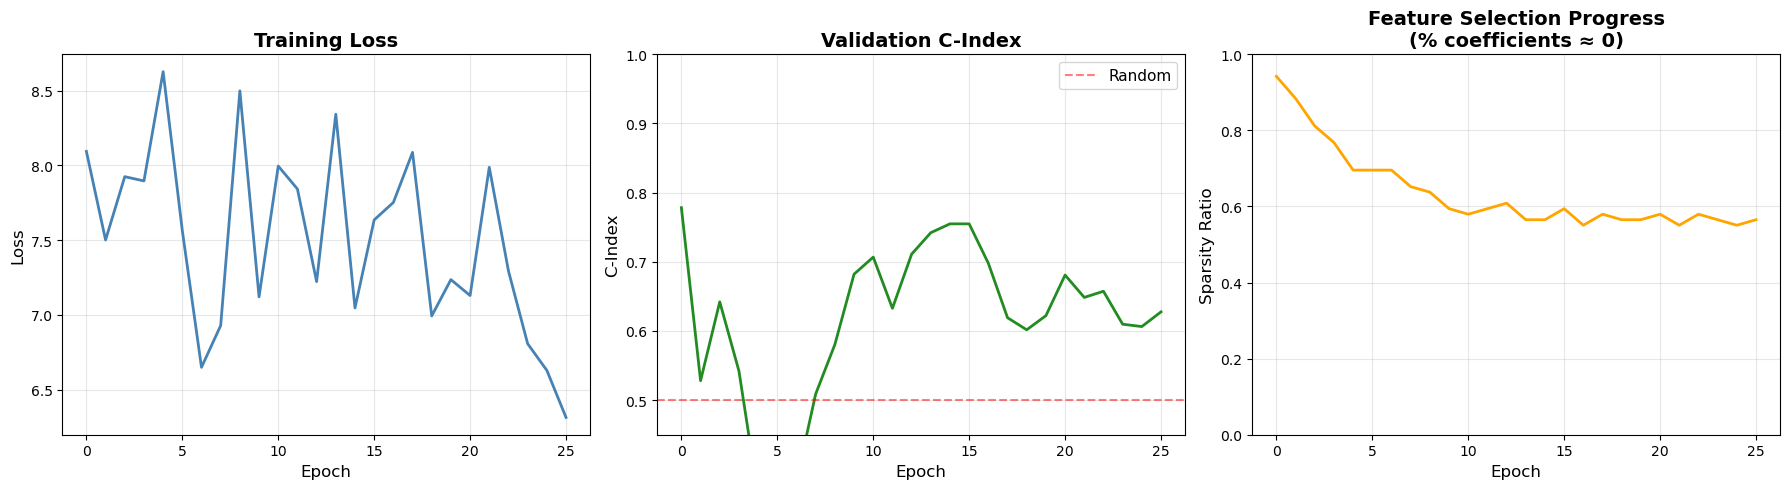

In [8]:
# Plot training progress
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss curve
axes[0].plot(train_losses, linewidth=2, color='steelblue')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title('Training Loss', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# C-index curve
axes[1].plot(val_cindices, linewidth=2, color='forestgreen')
axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('C-Index', fontsize=12)
axes[1].set_title('Validation C-Index', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([0.45, 1.0])

# Sparsity evolution
axes[2].plot(sparsity_ratios, linewidth=2, color='orange')
axes[2].set_xlabel('Epoch', fontsize=12)
axes[2].set_ylabel('Sparsity Ratio', fontsize=12)
axes[2].set_title('Feature Selection Progress\n(% coefficients ≈ 0)', fontsize=14, fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## Model Evaluation

In [9]:
# Get predictions with uncertainty
model.eval()
n_samples = 100  # Monte Carlo samples

train_predictions = []
test_predictions = []

with torch.no_grad():
    for _ in range(n_samples):
        train_log_hazards = model(X_train_tensor)
        train_predictions.append(train_log_hazards.cpu().numpy())
        
        test_log_hazards = model(X_test_tensor)
        test_predictions.append(test_log_hazards.cpu().numpy())

train_predictions = np.array(train_predictions)
test_predictions = np.array(test_predictions)

# Compute statistics
train_mean = train_predictions.mean(axis=0)
test_mean = test_predictions.mean(axis=0)

# C-Index
train_cindex = concordance_index_censored(
    event_train.astype(bool), time_train, train_mean
)[0]
test_cindex = concordance_index_censored(
    event_test.astype(bool), time_test, test_mean
)[0]

# Get coefficients
coef_mean, coef_std = model.get_coefficients()

# Count selected features
threshold = 0.01  # Consider coefficients < 0.01 as "zero"
selected = np.abs(coef_mean) >= threshold
n_selected = selected.sum()

print("=" * 70)
print("PERFORMANCE METRICS")
print("=" * 70)
print(f"\nConcordance Index (C-Index):")
print(f"  Training: {train_cindex:.4f}")
print(f"  Test:     {test_cindex:.4f}")
print(f"\nFeature Selection (Elastic Net):")
print(f"  Original features: {len(coef_mean)}")
print(f"  Selected features: {n_selected} ({n_selected/len(coef_mean)*100:.1f}%)")
print(f"  Removed features: {len(coef_mean) - n_selected} ({(len(coef_mean)-n_selected)/len(coef_mean)*100:.1f}%)")
print("=" * 70)

PERFORMANCE METRICS

Concordance Index (C-Index):
  Training: 0.8763
  Test:     0.6277

Feature Selection (Elastic Net):
  Original features: 69
  Selected features: 30 (43.5%)
  Removed features: 39 (56.5%)


In [10]:
# Analyze selected features
feature_names = X.columns.tolist()

# Create DataFrame with all coefficients
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef_mean,
    'Std': coef_std,
    'Lower_95CI': coef_mean - 1.96 * coef_std,
    'Upper_95CI': coef_mean + 1.96 * coef_std,
    'AbsCoef': np.abs(coef_mean),
    'Selected': np.abs(coef_mean) >= threshold
})

# Sort by absolute coefficient
coef_df = coef_df.sort_values('AbsCoef', ascending=False)

# Get selected features only
selected_df = coef_df[coef_df['Selected']].copy()

print("\n" + "=" * 90)
print(f"SELECTED FEATURES BY ELASTIC NET (|coefficient| >= {threshold})")
print("=" * 90)
print(f"{'Feature':<50s} | {'Coef':>8s} | {'Std':>7s} | {'95% CI':>20s}")
print("=" * 90)

for idx, row in selected_df.head(20).iterrows():
    feat_name = row['Feature'][:48]
    ci_str = f"[{row['Lower_95CI']:6.3f}, {row['Upper_95CI']:6.3f}]"
    print(f"{feat_name:<50s} | {row['Coefficient']:8.4f} | {row['Std']:7.4f} | {ci_str:>20s}")

print("=" * 90)
print(f"\nTotal selected: {len(selected_df)} / {len(coef_df)} features")


SELECTED FEATURES BY ELASTIC NET (|coefficient| >= 0.01)
Feature                                            |     Coef |     Std |               95% CI
Oestrogen receptor status at CB_1.0                |   0.1650 |  0.2152 |     [-0.257,  0.587]
Adjuvant therapy with bio drugs                    |  -0.1259 |  0.2094 |     [-0.536,  0.285]
Oestrogen receptor status at CB_2.0                |  -0.1164 |  0.2143 |     [-0.536,  0.304]
Her2 overexpression (with immunohystochemistry)    |  -0.0939 |  0.2131 |     [-0.512,  0.324]
Grade at CB_3.0                                    |   0.0775 |  0.2165 |     [-0.347,  0.502]
Age                                                |  -0.0749 |  0.2149 |     [-0.496,  0.346]
Her2 overexpression (with immunohystochemistry)    |   0.0716 |  0.2153 |     [-0.350,  0.494]
Progesterone receptor status at CB_1.0             |   0.0711 |  0.2181 |     [-0.356,  0.499]
cT_T4                                              |  -0.0667 |  0.2097 |     [-0.478, 

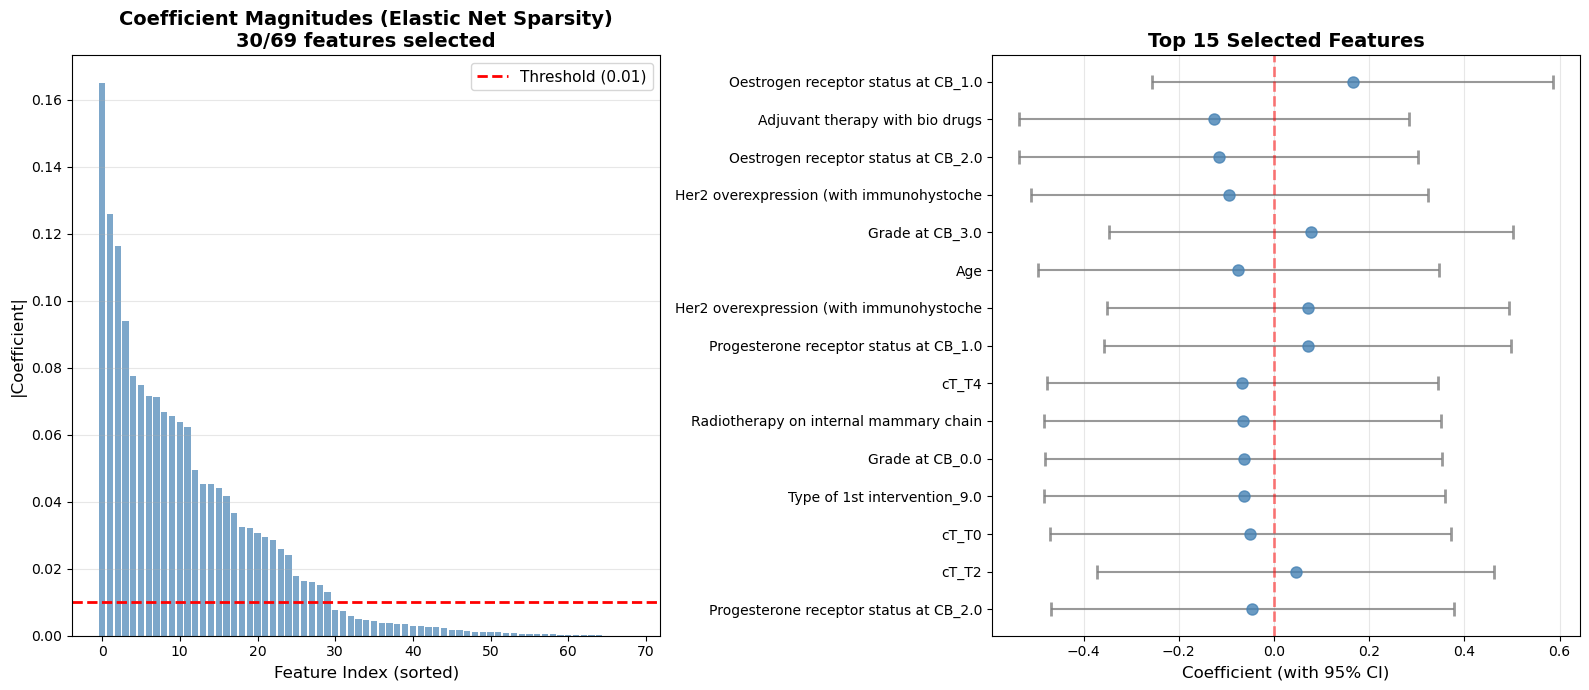

In [11]:
# Visualize selected features
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. All coefficients (to show sparsity)
coef_sorted = np.sort(np.abs(coef_mean))[::-1]
axes[0].bar(range(len(coef_sorted)), coef_sorted, color='steelblue', alpha=0.7)
axes[0].axhline(y=threshold, color='red', linestyle='--', linewidth=2, label=f'Threshold ({threshold})')
axes[0].set_xlabel('Feature Index (sorted)', fontsize=12)
axes[0].set_ylabel('|Coefficient|', fontsize=12)
axes[0].set_title(f'Coefficient Magnitudes (Elastic Net Sparsity)\n{n_selected}/{len(coef_mean)} features selected',
                  fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# 2. Selected features with uncertainty
plot_df = selected_df.head(15).iloc[::-1]  # Top 15, reversed for plotting

y_pos = np.arange(len(plot_df))
axes[1].errorbar(plot_df['Coefficient'], y_pos,
                 xerr=1.96*plot_df['Std'],
                 fmt='o', markersize=8, capsize=5, capthick=2,
                 color='steelblue', ecolor='gray', alpha=0.8)

axes[1].axvline(x=0, color='red', linestyle='--', alpha=0.5, linewidth=2)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([f[:40] for f in plot_df['Feature']], fontsize=10)
axes[1].set_xlabel('Coefficient (with 95% CI)', fontsize=12)
axes[1].set_title('Top 15 Selected Features', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

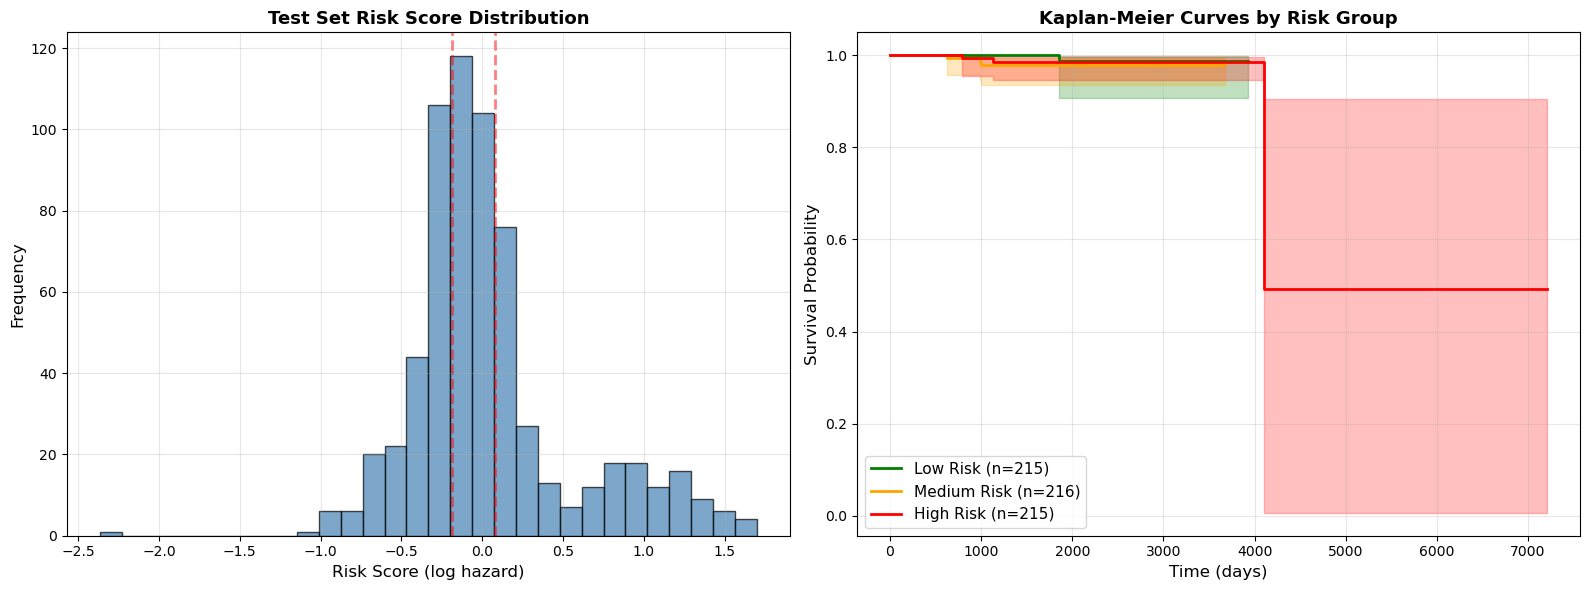


RISK GROUP COMPARISON (Log-Rank Test)
Low Risk vs Medium Risk: p-value = 0.3182
Low Risk vs High Risk: p-value = 0.5701
Medium Risk vs High Risk: p-value = 0.5910


In [12]:
# Risk stratification and Kaplan-Meier curves
risk_tertiles = np.percentile(test_mean, [33.33, 66.67])
risk_groups = np.digitize(test_mean, risk_tertiles)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Risk score distribution
axes[0].hist(test_mean, bins=30, alpha=0.7, color='steelblue', edgecolor='black')
for tertile in risk_tertiles:
    axes[0].axvline(tertile, color='red', linestyle='--', alpha=0.5, linewidth=2)
axes[0].set_xlabel('Risk Score (log hazard)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Test Set Risk Score Distribution', fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# 2. Kaplan-Meier curves by risk group
kmf = KaplanMeierFitter()
colors = ['green', 'orange', 'red']
labels = ['Low Risk', 'Medium Risk', 'High Risk']

for group in range(3):
    mask = risk_groups == group
    kmf.fit(time_test[mask], event_test[mask], label=f'{labels[group]} (n={mask.sum()})')
    kmf.plot_survival_function(ax=axes[1], ci_show=True, color=colors[group], linewidth=2)

axes[1].set_xlabel('Time (days)', fontsize=12)
axes[1].set_ylabel('Survival Probability', fontsize=12)
axes[1].set_title('Kaplan-Meier Curves by Risk Group', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11, loc='best')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Log-rank test
print("\n" + "=" * 70)
print("RISK GROUP COMPARISON (Log-Rank Test)")
print("=" * 70)
for i in range(3):
    for j in range(i+1, 3):
        mask_i = risk_groups == i
        mask_j = risk_groups == j
        result = logrank_test(
            time_test[mask_i], time_test[mask_j],
            event_test[mask_i], event_test[mask_j]
        )
        print(f"{labels[i]} vs {labels[j]}: p-value = {result.p_value:.4f}")
print("=" * 70)

## Wrap-up: elastic net vs lasso vs ridge

| Model | Regularization | Feature Selection | Stability | Best For |
|-------|---------------|-------------------|-----------|----------|
| **Ridge** | L2 only | No | High | All features matter |
| **Lasso** | L1 only | Yes | Low | Sparse solutions |
| **Elastic Net** | L1 + L2 | Yes | High | **Balanced approach** |

To push toward more sparsity (lasso-like), raise `l1_weight` (e.g. 0.1) and lower `l2_weight` (e.g. 0.01); for more stability (ridge-like) do the opposite (0.01 / 0.1). Equal weights (`l1_weight = l2_weight = 0.05`) is a fine starting point.

Roughly what I'd expect: C-Index somewhere between the lasso and ridge runs, moderate sparsity (maybe 30-50% of features dropped), more stable than pure lasso, less interpretable than pure ridge but simpler than the full feature set.